# Order-parameter composites: unsupervised $q$ tracking a physical $Q$

The paper's section-4 figure (iteration 7, 2026-10-29). The left column is the main case, 2:1 cross-frequency locking between resonant oscillator communities (the M24 varying-sensor-noise arm). The right column stacks three further systems: the measured electronic oscillators (ER sweep), the fine Stuart–Landau locked-to-unsteady sweep, and the collective period-two 2D coupled map lattice. In every panel $q$ is the centred PC1 of SPI–SPI $z$, fitted without $Q$, control or nuisance labels; $Q$ is computed independently from the physics. Code: [`composite_figures.py`](../composite_figures.py) (registry `SYSTEMS`). Every panel is also exported on its own (SVG, PDF, 600-dpi PNG) under `results/order-parameter-inference/composites-261021/panels/<system>/`. Text is typeset by LaTeX in Computer Modern when `latex` and `dvipng` are available, with a native Computer Modern-math fallback otherwise; the last section writes Helvetica renditions too.

**Reading the figure.** (a) Control against $Q$ (black, left axis, physical units) and $q$ (teal, right axis). Lines are means over held instances, and bands are their 10–90% range (not confidence intervals). The hardware has one recording per setting. $q$ is a PC score with arbitrary scale and sign, so its axis carries no ticks. Each inset is a robust-scaled MTS heatmap (boxed; locking communities A/B/C marked on the first) of a short window of one recording, with a physical glyph above it and a leader line to its control on $Q$. Legends give $|\rho_s|$ with $Q$. (b) $Q$ against mean-$|r|$ and mean-MPI PC1, without ticks. (c) $z_{ab}$ for named feature pairs against control on a fixed $[-1,1]$ range; triangles mark the snapshot controls. (d) Edge planes: SPI $a$ against SPI $b$ across all $M(M-1)$ ordered channel pairs of the snapshot recordings, in the same columns as (c); $z$ is written in the corner that is emptiest across the row. (e–g) Compact panels: heatmaps with glyphs above the curves. $Q$ (left axis) is overlaid with $q$, mean-$|r|$ and mean-MPI PC1, each affinely rescaled so its mean curve spans $[0,1]$. Bands are drawn for $Q$ and $q$ only. The mean-MPI sign is arbitrary and is shown correlating positively with $q$; display only, no statistic changes.

**Trajectories or bands.** Bands are the default. In locking every control–seed pair is an independent realisation, so faint lines joining equal seed indices would suggest paths that do not exist. Bands also keep the overlaid right-column panels legible. A trajectory version is kept below. It shows something bands hide: in Stuart–Landau, Kuramoto and CML2D, where seeds are paired across controls, individual instances step more sharply than their mean.

**What is claimed.** $q$ tracks $Q$ across controls. This is not a calibration of $Q$, not a mechanism, and not superiority over simple statistics: in hardware, Stuart–Landau and CML2D the baselines track $Q$ as well or better by rank. Feature names follow what calibration supports.

**Snapshots** follow fixed rules, never $Q$ or $q$. Locking: the held recordings with sensor noise nearest $\eta=.6$ at $\gamma=0,.10,.20$ (start, transition, end). The $\gamma=.20$ MPI was fetched read-only from Gadi and matches the archived hash. Hardware: ER settings 0, 23 (the last setting with phase slips) and 87. Stuart–Landau: instance 0 at $\gamma=.68$, $.725$ (the steepest interval) and $.77$. Kuramoto: the first held seed. CML2D: the fixed pilot seed of the three-systems figure; the curves are the 32-seed confirmation bank.

**Glyphs (defaults).** Locking: the wrapped slow–fast phase $\Phi(t)=\arg Z_B-\arg Z_{A,2}$, the quantity whose time-averaged phasor on a later window defines $Q$. Hardware: the wrapped carrier phase of the four late-locking channels (12/18/21/24) relative to the most coherent core channel. Stuart–Landau and Kuramoto: the global order-parameter magnitude $R(t)$. CML2D: the whole 256 × 256 lattice (archived state after the reference window), with the 32 observed sites circled. Every glyph is regenerated from the archived generator and checked against the archived input. Heatmaps show 80 samples (locking), 0.08 s (hardware), 150 and 200 samples (Stuart–Landau, Kuramoto) and 40 steps (CML2D), so individual oscillations are resolved.

In [1]:
import io
import sys
from pathlib import Path
ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents) if (p/'src/mtsspi/spi_spi_contract.py').is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
from PIL import Image as PILImage
from IPython.display import Image, display
from research.inference.benchmarks import composite_figures as cf
pd.set_option('display.width', 220)

def show(path, width=1500):
    """Display a downsampled preview; the saved PNG/SVG/PDF files are full resolution."""
    image = PILImage.open(path)
    image.thumbnail((width, 10*width))
    buffer = io.BytesIO(); image.save(buffer, format='PNG')
    display(Image(data=buffer.getvalue()))

systems = {name: cf.load(name) for name in ('locking', 'hardware', 'stuart-landau', 'kuramoto', 'cml2d')}
locking, hardware, sl, kuramoto, cml = systems.values()
pd.DataFrame({name: {k: d.metrics[k] for k in ('q', 'mean-|r|', 'mean-MPI')} for name, d in systems.items()}).round(3)

,locking,hardware,stuart-landau,kuramoto,cml2d
q,0.871,0.892,0.886,0.826,0.883
mean-|r|,0.032,0.950,0.915,0.998,0.966
mean-MPI,0.020,0.982,0.883,0.994,0.973


## Feature contract and replay checks

$z$ must use all $M(M-1)$ ordered off-diagonal entries (`unified_ordered_v3`). For each locking and hardware snapshot recording, the whole stored $z$ row (41,616 coordinates) is rebuilt from the archived MPIs with the library builder and compared with the bank; each displayed edge profile is replayed. The legacy upper-symmetrised value is listed alongside: it differs for the directed LCSS × TE pair, so the check can tell the contracts apart. The locking replay reproduces the archived noisy observations exactly. Stuart–Landau and Kuramoto glyphs come from regenerated trajectories that match the archived inputs (to float32 precision for Stuart–Landau). CML2D $q$ values are replayed from the frozen model by `three_systems.load_cml`.

In [2]:
checks = pd.DataFrame([dict(system=name, record=c['row_id'], **{k: v for k, v in c.items() if k != 'row_id'})
                       for name, d in systems.items() for c in d.provenance.get('snapshot_checks', [])])
checks['row_contract'] = checks.row_contract.map(lambda c: c if isinstance(c, float) else f"passes={c['passes']}, max error {c['max_error']:.1e}")
display(checks)
edges = pd.DataFrame([dict(system=d.spec.name, **r) for d in (locking, hardware) for r in d.provenance['edge_receipts']])
edges.assign(feature=edges.feature.str.replace('\n', ' ', regex=False)).round(4)

,system,record,observation_replay_max_error,row_contract,regeneration_max_error
0,locking,xfreq21-random-noise-g000-s209,0.0,"passes=True, max error 8.7e-17",NaN
1,locking,xfreq21-random-noise-g100-s212,0.0,"passes=True, max error 7.2e-17",NaN
2,locking,xfreq21-random-noise-g200-s215,0.0,"passes=True, max error 9.3e-17",NaN
3,hardware,r17451096-s000-t5000,NaN,"passes=True, max error 0.0e+00",NaN
4,hardware,r17451096-s023-t5000,NaN,"passes=True, max error 0.0e+00",NaN
5,hardware,r17451096-s087-t5000,NaN,"passes=True, max error 0.0e+00",NaN
6,stuart-landau,M32_T1000_I0_gamma0p680,NaN,NaN,2.980128e-08
7,stuart-landau,M32_T1000_I0_gamma0p725,NaN,NaN,2.979974e-08
8,stuart-landau,M32_T1000_I0_gamma0p770,NaN,NaN,2.980179e-08
9,kuramoto,kuramoto-k0.6250-s260916009-m32-t1000,NaN,NaN,0.000000e+00


,system,row_id,feature,z,stored,legacy_upper_symmetrized
0,locking,xfreq21-random-noise-g000-s209,LCSS $\times$ TE,0.6157,0.6157,0.7486
1,locking,xfreq21-random-noise-g000-s209,Johansen $\times$ Johansen,-0.4934,-0.4934,-0.4934
2,locking,xfreq21-random-noise-g000-s209,Pearson lag 2 $\times$ lag 20$^2$,0.3689,0.3689,0.3689
3,locking,xfreq21-random-noise-g100-s212,LCSS $\times$ TE,0.5140,0.5140,0.6350
4,locking,xfreq21-random-noise-g100-s212,Johansen $\times$ Johansen,-0.1522,-0.1522,-0.1522
5,locking,xfreq21-random-noise-g100-s212,Pearson lag 2 $\times$ lag 20$^2$,-0.7134,-0.7134,-0.7134
6,locking,xfreq21-random-noise-g200-s215,LCSS $\times$ TE,-0.1445,-0.1445,-0.1700
7,locking,xfreq21-random-noise-g200-s215,Johansen $\times$ Johansen,0.1028,0.1028,0.1028
8,locking,xfreq21-random-noise-g200-s215,Pearson lag 2 $\times$ lag 20$^2$,-0.7818,-0.7818,-0.7818
9,hardware,r17451096-s000-t5000,kernel SI $\times$ IDS,0.8962,0.8962,0.8962


## Composite, default: bands

The main headline grows to balance the column heights.

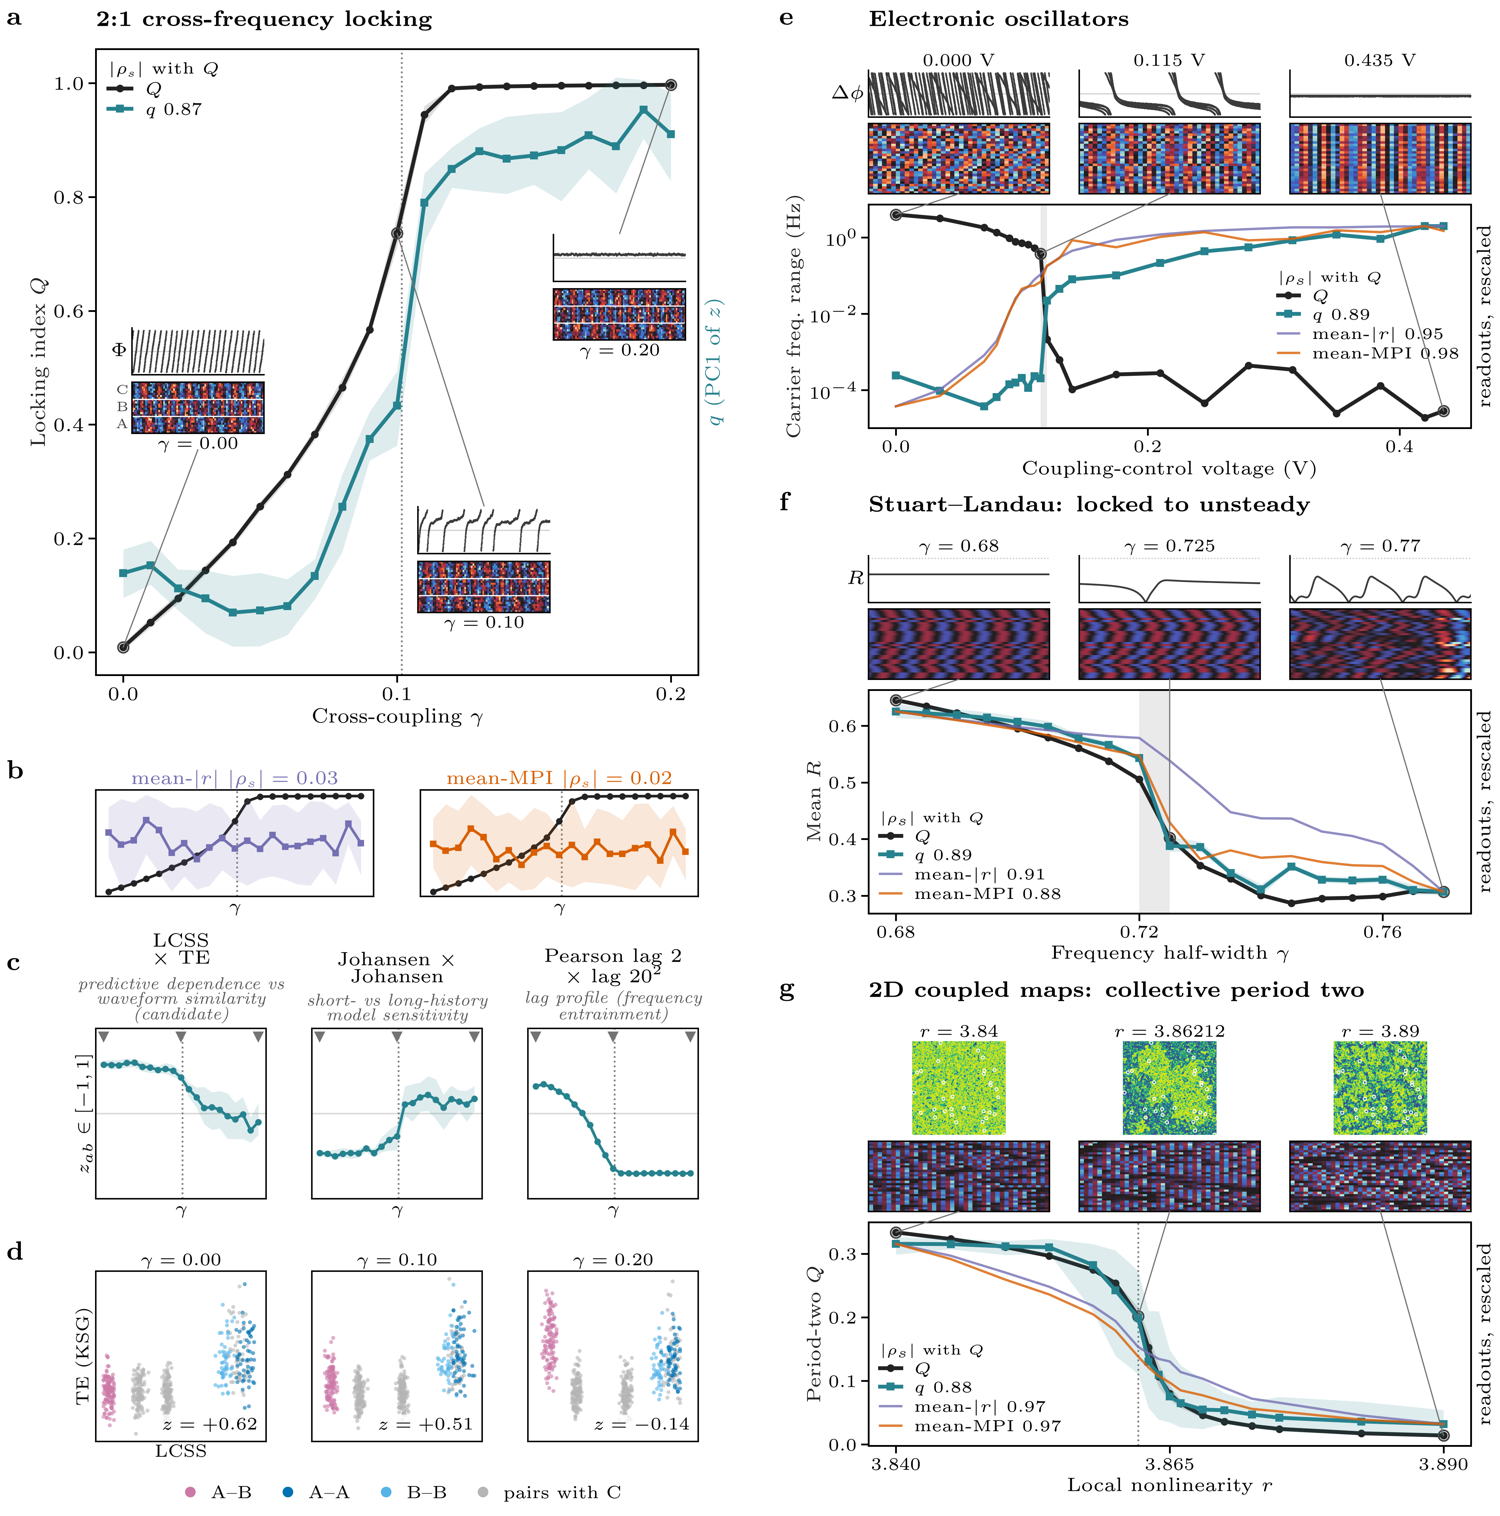

In [3]:
show(cf.save(cf.composite_stacked(locking, [hardware, sl, cml]), 'composite-stacked-band'))

## The same with faint instance trajectories

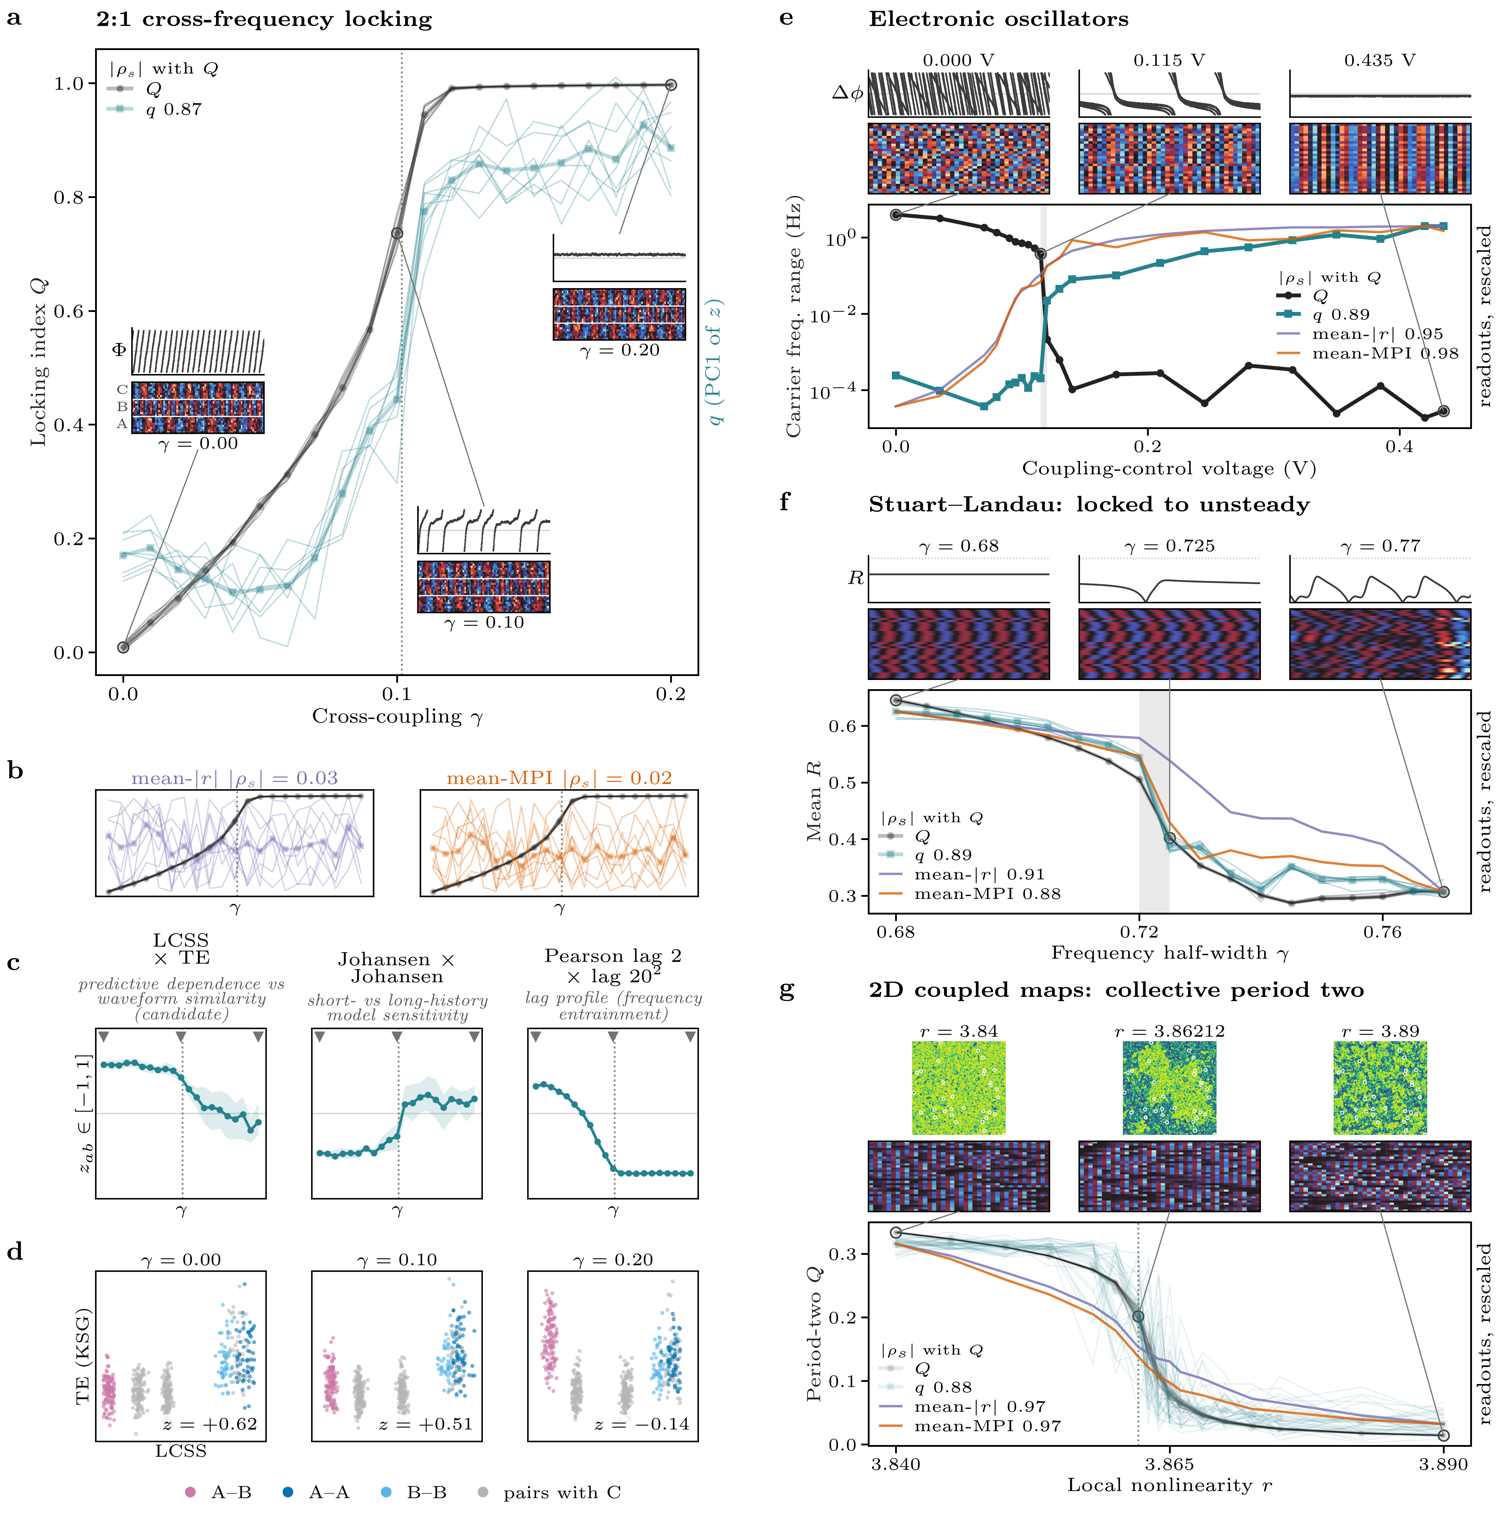

In [4]:
show(cf.save(cf.composite_stacked(locking, [hardware, sl, cml], spread='trajectories'), 'composite-stacked-trajectories'))

## Alternative middle panel: Kuramoto instead of Stuart–Landau

At $M=N=32$ the Kuramoto sweep is a gradual finite-size crossover with wide seed spread. Its $q$ is the weakest of the candidate systems (.83), the PC1-dominance screen was not met, and mean-$|r|$ (1.00) and mean-MPI (.99) are near-perfect, because synchronisation strength is the order parameter here. Stuart–Landau is recommended for the panel; see the notes below.

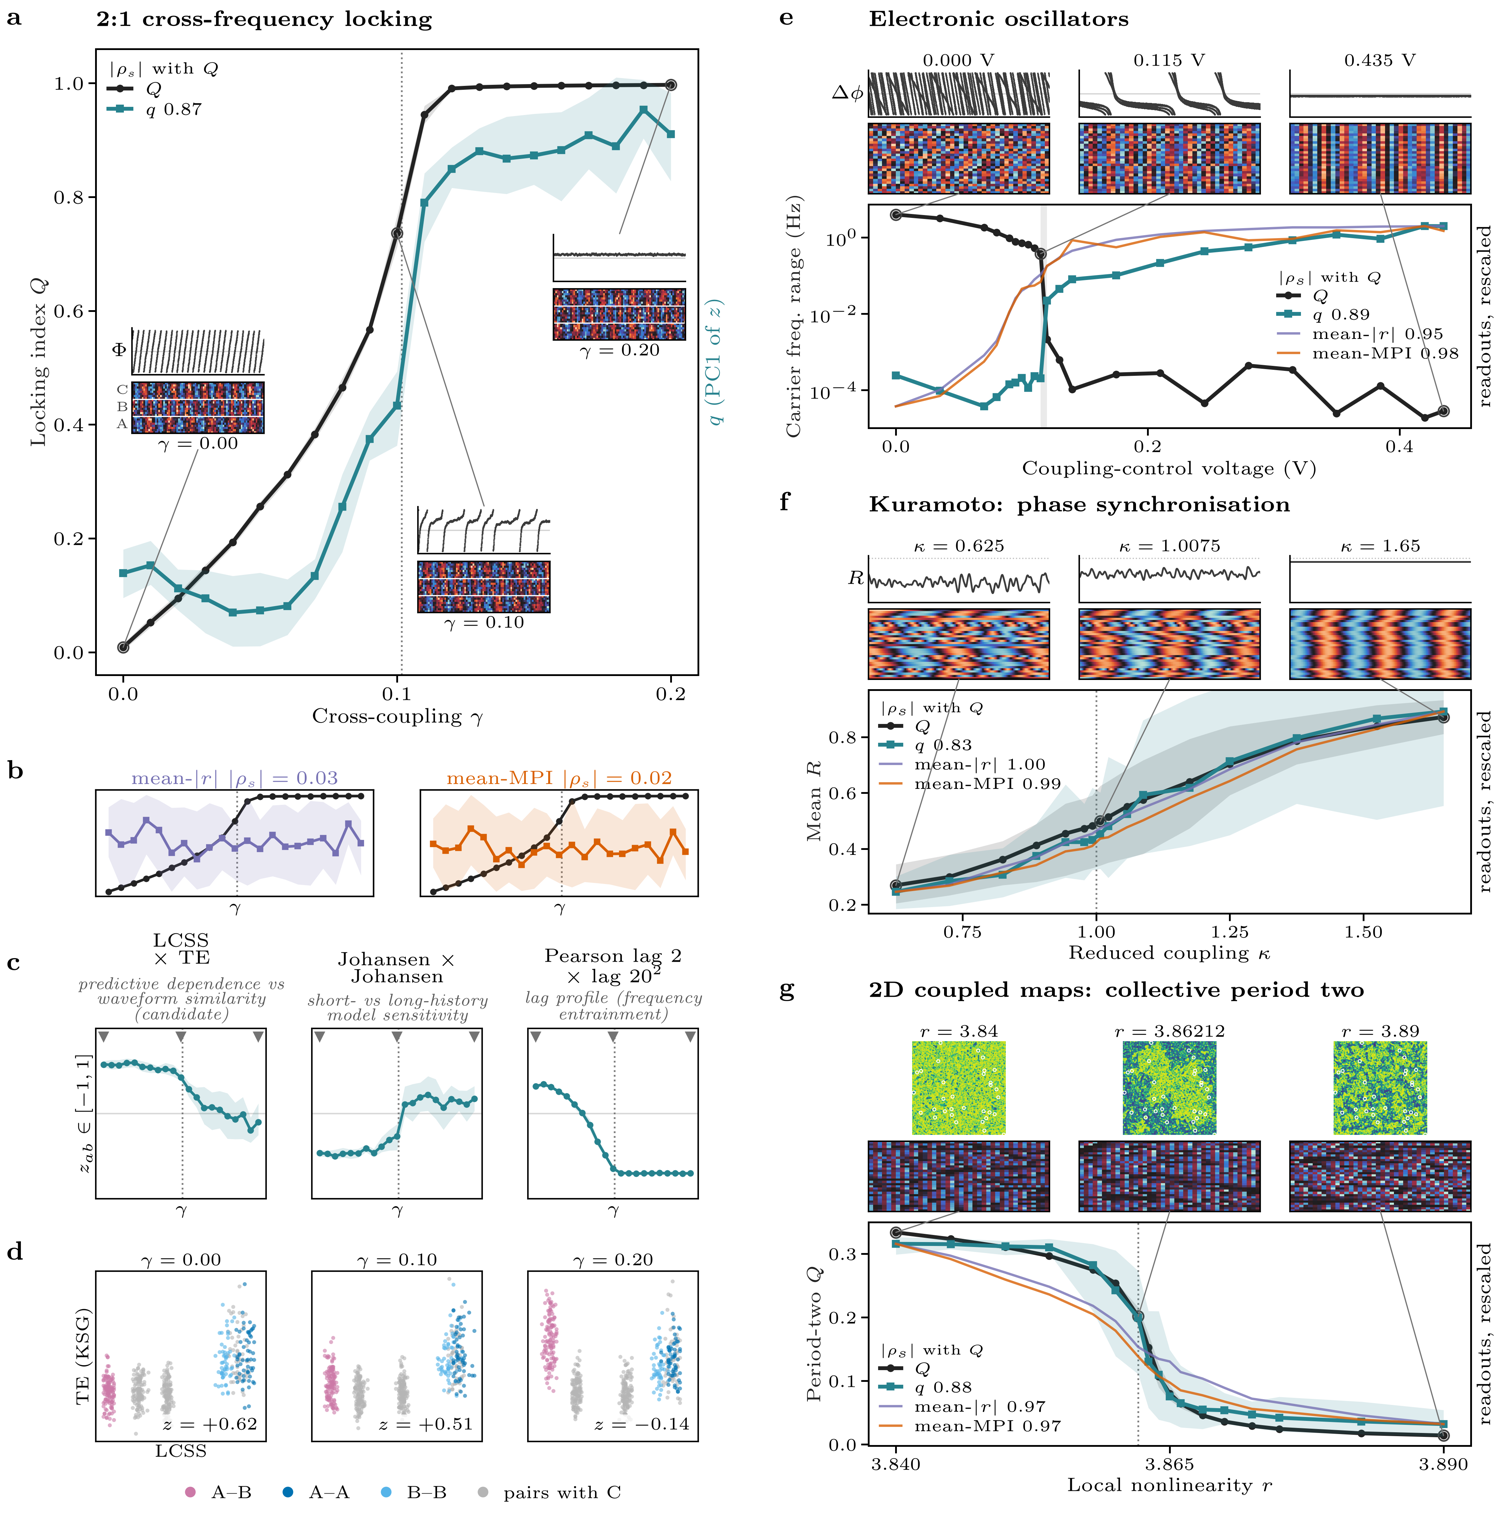

In [5]:
show(cf.save(cf.composite_stacked(locking, [hardware, kuramoto, cml]), 'composite-stacked-kuramoto'))

## Glyph options

All variants at the three snapshots. Locking: wrapped $\Phi$ (default), spiral ($\Phi$ as angle, time as radius), Lissajous ($\cos\arg Z_A$ against $\cos\arg Z_B$ over 60 time units). Hardware: wrapped late-channel phase (default), $R(t)$, phase raster. CML2D: lattice (default) or the global mean $\bar x(t)$ over 40 steps.

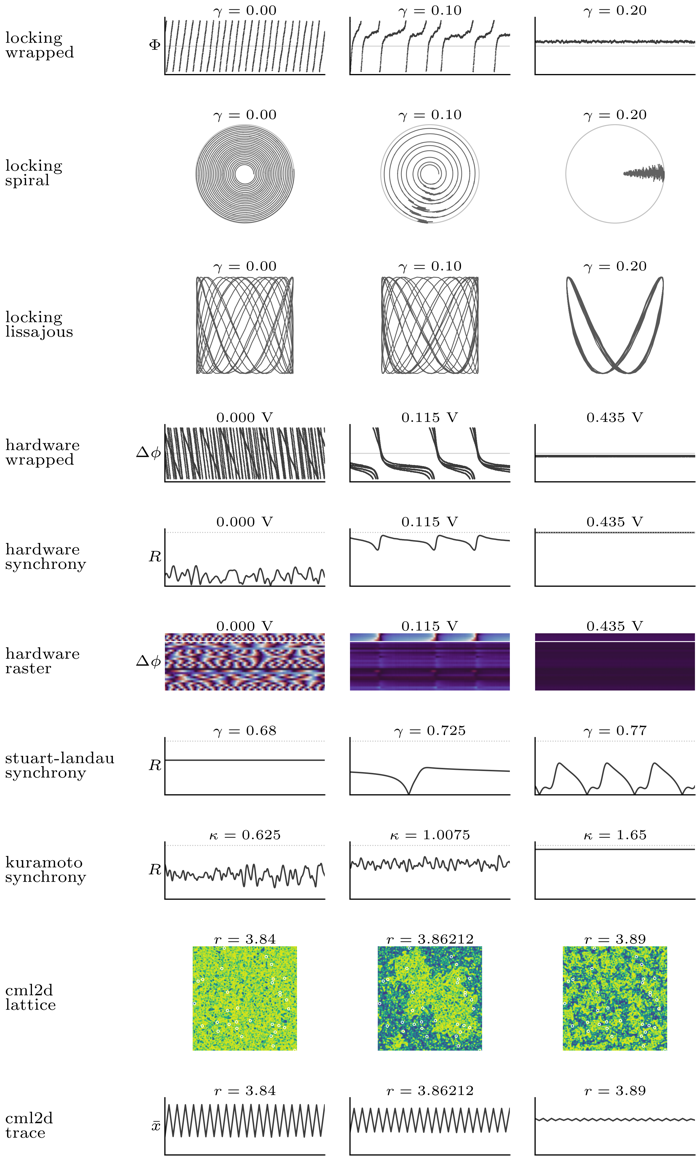

In [6]:
show(cf.save(cf.glyph_gallery([locking, hardware, sl, kuramoto, cml]), 'glyph-gallery'), width=700)

## Hardware: which physical quantity?

No universal order parameter is known for this apparatus. **Default:** the across-channel range of mean carrier frequency (log axis), whose collapse marks the cessation of phase slips at 23→24. **Alternatives:** mean carrier phase coherence $R_1$ (almost a monotone function of mean-$|r|$: rank correlation 1.00 on ER), the temporal SD of $R(t)$, or the fraction of frequency-locked channels (needs a threshold). With $R_1$, $q$'s rank association is similar, but $Q$ no longer shows the step that $q$ shows at slip cessation.

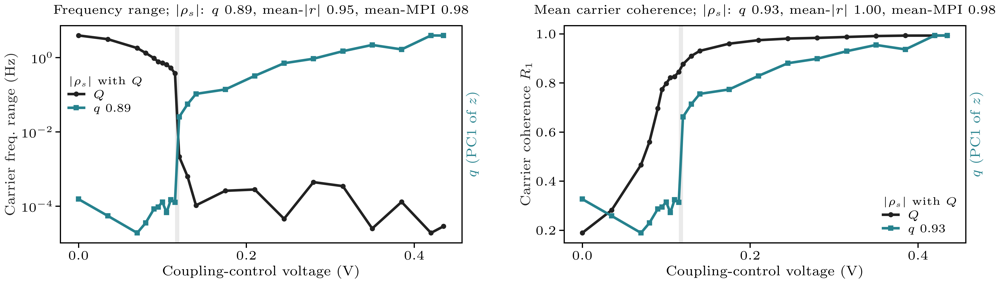

In [7]:
hardware_r1 = cf.load('hardware', Q_source='R1', Q_label='Carrier coherence $R_1$', Q_log=False, legend_loc='lower right')
show(cf.save(cf.compare_Q([hardware, hardware_r1], ['Frequency range', 'Mean carrier coherence']), 'hardware-Q-alternatives'), width=1000)

## Baselines: where simple statistics do as well

| system | $q$ | mean-$\lvert r\rvert$ | mean-MPI PC1 | rows |
|---|---|---|---|---|
| locking (held) | .871 | .032 | .020 | 168 |
| hardware ER, settings ≤ 87 | .892 | .950 | .982 | 22 |
| Stuart–Landau fine | .886 | .915 | .883 | 152 |
| Kuramoto, $M=N=32$ | .826 | .998 | .994 | 128 |
| CML2D confirmation | .883 | .966 | .973 | 544 |

Values are $|\rho_s|$ with $Q$. Only locking separates $q$ from both baselines; there the advantage is the ordering of variation under recording-specific noise, not information absent from the means (a supervised mean-vector readout reaches .900). In hardware the descriptive difference is localisation: $q$ crosses 43% of its displayed range over the slip-cessation interval 23→24, against 4.5% for mean-$|r|$ and 8.9% for mean-MPI ([baselines notebook](order-parameter-benchmarks-baselines.ipynb), section 7).

## Notes on the open questions

**Locking glyph: wrapped $\Phi$ is recommended.** It is the quantity $Q$ summarises ($Q=|\langle e^{i\Phi}\rangle|$ on a later window), so the glyph and the curve read as one object. It separates all three snapshots at a glance (continuous sawtooth, intermittent slips, flat band) and is scale-free. It also shares its visual language with the hardware glyph. The Lissajous is the most familiar picture of 2:1 locking, but over any fixed window it shows $\gamma=.10$ as a filled box like $\gamma=0$: it hides partial locking, exactly the transition state. It also depends on the window length and on the latent community mean fields rather than anything observed. The spiral encodes the same information as $\Phi$ but is denser and harder to read at inset size.

**Stuart–Landau over Kuramoto.** (i) The fine Stuart–Landau sweep is an independent confirmation: a frozen coordinate on 152 fresh rows, with every pre-outcome gate passed. The $M=N=32$ Kuramoto result is exploratory, since its PC1-dominance screen was not met. (ii) The Stuart–Landau transition is sharp, and $q$, mean $R$ and $\mathrm{sd}_t(R)$ have the same steepest interval (.720–.725). At $N=32$ Kuramoto is a gradual crossover, with $q$'s steepest interval adjacent to $Q$'s. (iii) Locked-to-unsteady changes the temporal character of the collective dynamics (constant against oscillating $R$), which fits the paper's character-first framing. Kuramoto synchronisation is strength itself, so mean-$|r|$ reaches .998 and $q$ (.826) looks weakest exactly where the framing says it should not be used. Kuramoto is probably the better-known model (inferred from its standing as the canonical synchronisation model, not measured), but recognition does not outweigh (i)–(iii). The Stuart–Landau path is Matthews & Strogatz's $K=.8$ cut, which keeps a classical reference.

**CML2D: what to show.** $Q$ is the period-two amplitude of the spatially averaged state on a disjoint future window. The default glyph is the whole lattice with the observed sites circled. It shows why $Q$ falls: one period-two phase fills the lattice at $r=3.84$, large domains of both phases coexist near $3.862$, and fine domains at $3.89$ average the collective oscillation away. It also shows that 32 scattered sensors sample this structure. Caveat: the lattice is the archived state after the reference window, not simultaneous with the observed window, and comes from the pilot seed. The alternative, the global mean $\bar x(t)$ (a large zigzag when ordered), is $Q$ itself and so partly redundant with the curve.

**Edge-plane groups.** Within-community pairs are split into A–A and B–B (two blues), and C–C joins the pairs involving the reference community C. For LCSS × TE the split adds little: A–A, B–B and C–C sit together (LCSS ≈ .9, TE ≈ .05), and the change is in the A–B pairs (TE .00 → .06 at almost constant LCSS ≈ .78). The split matters for the other two locking pairs, so one scheme serves any edge row. For Pearson lag 2 × lag 20², A–A and B–B move apart: at γ = 0.14 the A–A centroid is (.35, .00) and B–B is (−.44, .56), the documented within-community redistribution. For Johansen, B–B separates on the trace axis.

**Statistics placement.** $|\rho_s|$ with $Q$ sits in the legends: each number is bound to its curve's colour and symbol, and the legend is needed anyway to identify four overlaid curves. A grey one-liner would repeat the legend's names, and defining $Q$ in-panel needs symbols that only the caption can define.

**Hardware $Q$ and range.** Keep the carrier frequency range on settings ≤ 87. It measures the calibrated event, the cessation of phase slips, and it steps exactly where $q$ steps. $R_1$ is effectively a strength measure (rank correlation 1.00 with mean-$|r|$), so choosing it would turn $Q$ into a baseline. Beyond 0.435 V the grid is sparse (six settings to 3.5 V), $q$ dips at 0.875 V without a change in $Q$, and the calibrated spectral explanation fails at settings 175–437. The caption should say that $q$ is fitted on all 29 ER recordings and give the full-sweep association (.822).

**Which systems have $M<32$?** Locking: $M=24$ (with an $M=48$ confirmation); hardware: $M=28$. Fine Stuart–Landau and full Kuramoto: $M=N=32$ only. The broad Stuart–Landau sweep ($\gamma=.55$–$1.25$) has separate $M=N=8,16,32$ systems at $T=100/500/1000$. CML2D has paired $M=16$ views at $T=500$ and $1000$ (288 rows each, nested sensors from the same masters, 9 old-grid controls) beside the primary $M=32$. All panels use $M=32$ or the full system.

## Which pairs carry the locking signal, and which SPIs see the coupling?

Retrospective and descriptive, using the 24 held records at $\gamma=0,.10,.20$ (8 seeds each; MPIs fetched read-only from Gadi and hash-checked) and every one of the 25,417 PC1-eligible coordinates. Code: [`locking_character_axes.py`](../locking_character_axes.py). *Coupling signal*: change in the mean over A–B pairs minus pairs with C, from $\gamma=0$ to $.20$, in units of the SPI's spread over pairs. *A–B share*: the fraction of a coordinate's $z$ change that disappears when the A–B pairs are removed.

In [8]:
from research.inference.benchmarks import locking_character_axes as lca
order, recs = lca.records()
spis = lca.spi_shifts(order, recs)
display(spis.groupby('family').agg(SPIs=('spi', 'size'), median_abs_coupling=('coupling', lambda x: x.abs().median()),
        share_t_above_3=('coupling_t', lambda x: (x.abs() > 3).mean())).sort_values('median_abs_coupling', ascending=False).round(2))
coords = lca.classify(lca.coordinate_changes(order, recs))
display(coords.carrier.value_counts().to_frame('clean trackers'))
display(coords.groupby('carrier').families.value_counts().groupby(level=0).head(4).to_frame('coordinates'))
coords[coords.carrier.eq('A–B pairs')].nlargest(8, 'abs_rho_Q')[['rank', 'spi_a', 'spi_b', 'abs_rho_Q', 'abs_rho_eta', 'z_gamma0', 'z_gamma20', 'AB_share']].round(2)

,SPIs,median_abs_coupling,share_t_above_3
family,,,
transfer and directed information,5,2.14,0.60
kernel and distance dependence,3,0.24,1.00
cointegration,11,0.21,0.64
other information-theoretic,29,0.18,0.55
envelope correlation,6,0.06,0.00
distance and shape similarity,27,0.05,0.11
spectral coherence and phase,54,0.02,0.02
directed spectral / Granger,50,0.02,0.10
linear and rank correlation,68,0.00,0.00


,clean trackers
carrier,
within communities,330
A–B pairs,231
mixed,38


coordinates
carrier            families                                                       
A–B pairs          linear and rank correlation × transfer and dire...           66
                   distance and shape similarity × transfer and di...           40
                   other information-theoretic × transfer and dire...           32
                   directed spectral / Granger × transfer and dire...           24
mixed              cointegration × other information-theoretic                  15
                   linear and rank correlation × transfer and dire...            9
                   cointegration × transfer and directed information             7
                   linear and rank correlation × other information...            5
within communities linear and rank correlation × linear and rank c...          193
                   directed spectral / Granger × linear and rank c...           43
                   linear and rank correlation × other information...           37
                   cointegration × linear and rank correlation                  30

,rank,spi_a,spi_b,abs_rho_Q,abs_rho_eta,z_gamma0,z_gamma20,AB_share
16880,127,lcss,si_kernel_W-0.5_k-1,0.91,0.03,0.81,0.24,0.87
17003,128,lcss_constraint-itakura,si_kernel_W-0.5_k-1,0.91,0.03,0.81,0.24,0.87
17126,129,lcss_constraint-sakoe-chiba,si_kernel_W-0.5_k-1,0.91,0.03,0.81,0.24,0.87
13902,1007,corr_kendall_tau-10-sq,si_kernel_W-0.5_k-1,0.91,0.09,0.65,0.34,0.63
13607,730,corr_kendall_tau-5-sq,si_kernel_W-0.5_k-1,0.91,0.07,0.91,0.55,0.69
9057,788,corr_pearson_tau-5-sq,si_kernel_W-0.5_k-1,0.91,0.03,0.92,0.57,0.72
11430,789,corr_spearman_tau-5-sq,si_kernel_W-0.5_k-1,0.90,0.03,0.92,0.57,0.72
16875,664,lcss,xme_kozachenko_k10,0.90,0.12,-0.89,-0.50,0.75


In [9]:
lca.frequency_check().round(3)

,gamma,community,omega,ratio,r_lag2,cos_1u,r2_lag20,cos2_10u
0,0.0,A,0.998,2.302,0.388,0.542,0.365,0.719
1,0.0,B,2.299,2.302,-0.469,-0.665,0.144,0.297
2,0.2,A,1.101,2.000,0.323,0.453,0.000,0.000
3,0.2,B,2.202,2.000,-0.422,-0.590,0.504,0.999


- **Two kinds of clean trackers.** Clean means $|\rho_s(Q)|\ge.8$, $|\rho_s(\eta)|\le.2$ and $|\Delta z|\ge.3$. Most are carried by within-community pairs, dominated by lagged-correlation × lagged-correlation pairs, and these hold most of the PC1 weight. A large minority are carried by the A–B pairs.
- **Which SPIs see the 2:1 coupling.** Linear and rank correlation, partial correlation, spectral coherence and phase, and most spectral Granger measures do not move on A–B pairs: $\sin\phi$ and $\sin2\phi$ are linearly uncorrelated. Transfer entropy, kernel stochastic interaction, CDS, lag-1 MI and conditional entropies do. Nearly every A–B-carried coordinate pairs one coupling-blind SPI (correlation, LCSS, DTW, partial correlation, coherence) with one coupling-sensitive SPI. The cleanest are LCSS × kernel SI ($|\rho_s(Q)|$ .91, noise .03) and LCSS × TE (.89, .08).
- **The lag-2 × lag-20² axis reads entrained frequencies.** Inside a synchronised community the lagged correlation follows $\cos(\omega\tau)$. Locking pulls the frequencies from (1.00, 2.30) to (1.10, 2.20), exactly 2:1. At lag 10 time units this sends A–A's squared correlation to 0, since $\cos(11.0)\approx0$, and B–B's towards its noise-limited maximum. The flip is real but specific to the lag grid relative to the oscillation periods. It is a frequency (entrainment) readout, not a reading of A–B dependence.

Two character axes are nameable at a useful level of generality. **Lag-profile organisation:** how dependence is spread over lags, here driven by frequency entrainment; it recurs in the hardware as Pearson 2 ms × 20 ms. **Dependence without waveform alignment (cross-frequency dependence):** coupling seen by information-theoretic SPIs but not by correlation, coherence or waveform-similarity SPIs; here it is calibrated by construction (2:1 harmonic locking). The second is the one about the coupling itself.

## Alternatives

Pearson lag 2 × lag 20² gives the geometrically cleanest edge plane (four tight block clusters), but it reads frequency entrainment within communities.

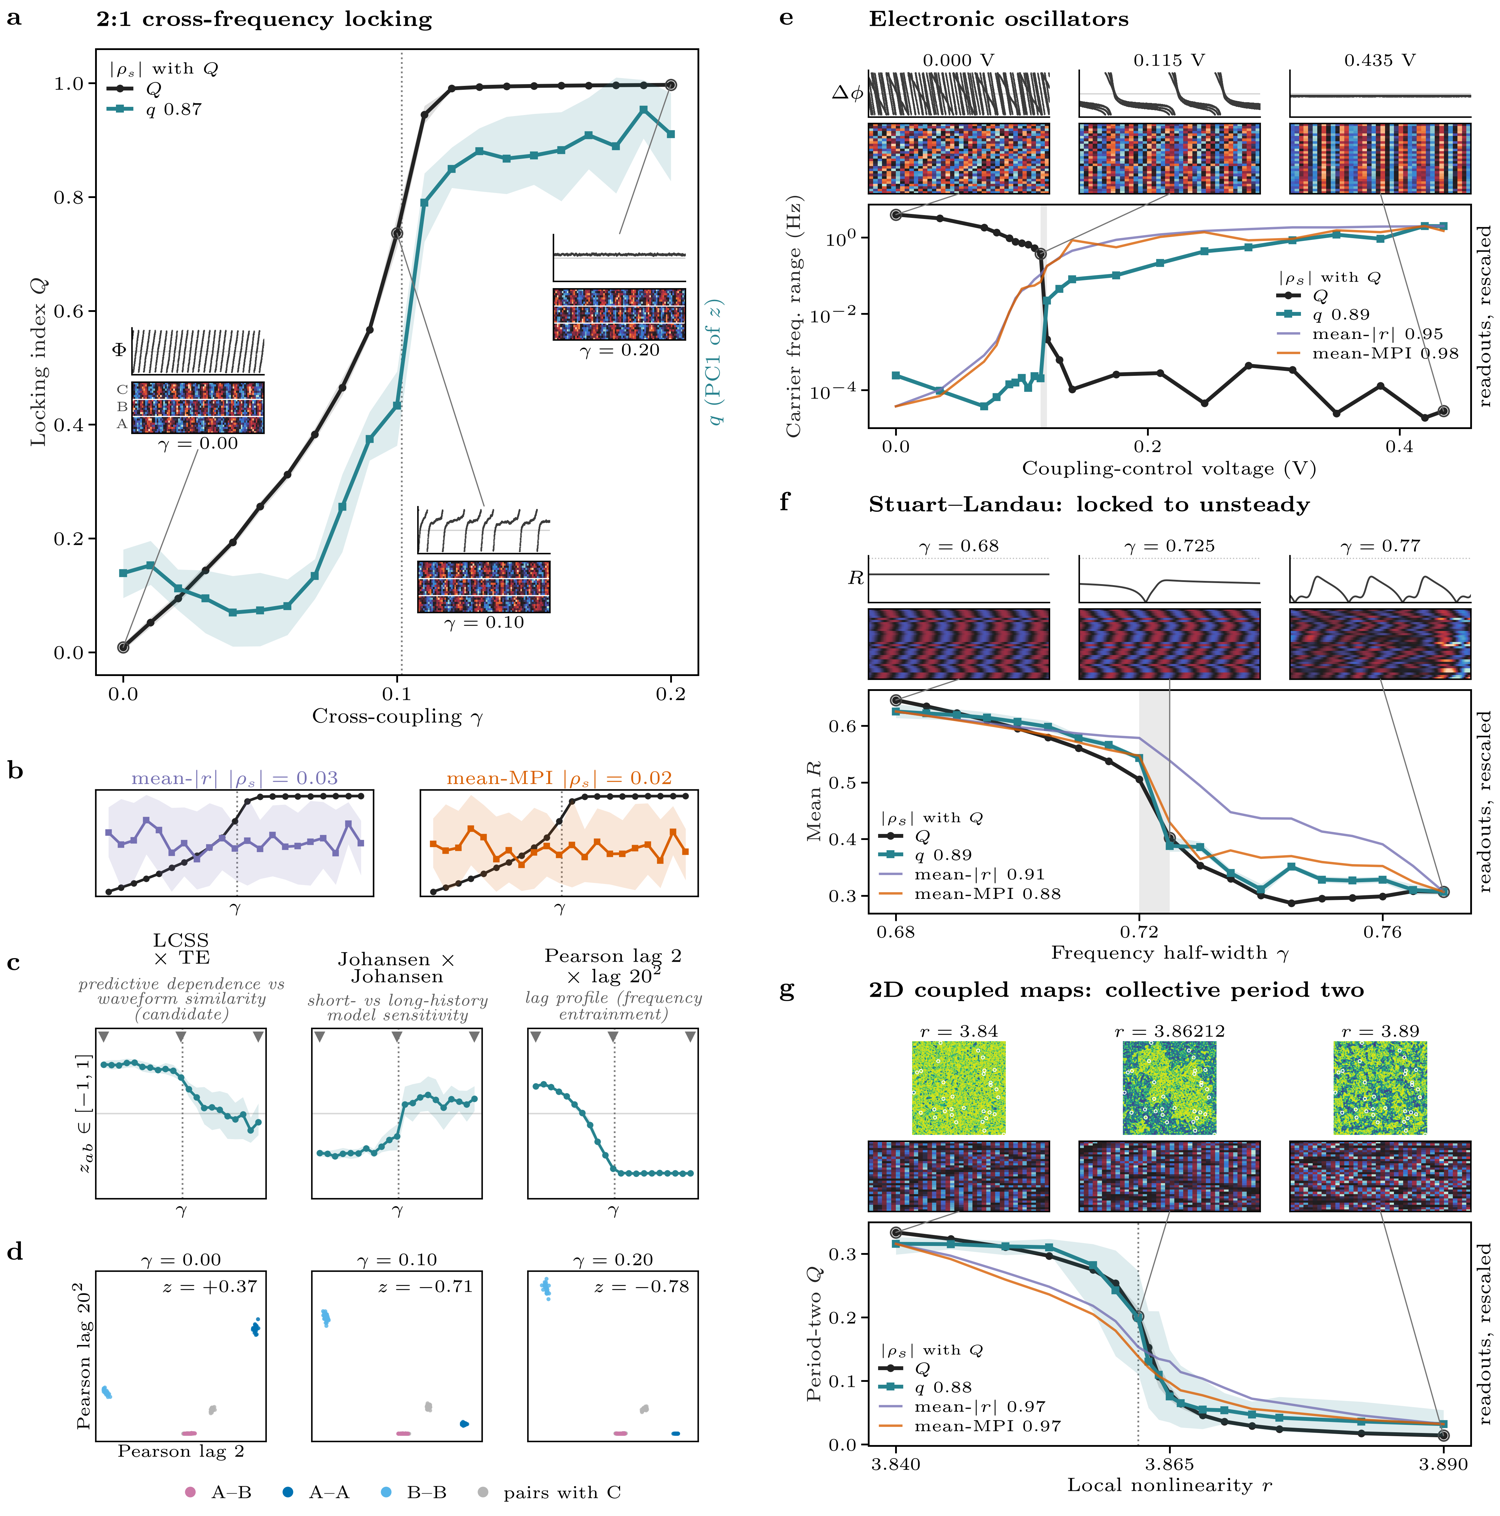

In [10]:
show(cf.save(cf.composite_stacked(locking, [hardware, sl, cml], edge_rows=(2,)), 'composite-stacked-lag-edges'))

**Version with LCSS × kernel SI in the middle of (c).** The Johansen pair nearly copies the lag-pair panel ($r\approx.98$ across held records). Replacing it with LCSS × kernel SI shows the coupling axis under a second estimator: the same A–B-carried pattern with a cleaner noise profile ($|\rho_s(Q)|$ .91, noise .03). The edge planes in (d) stay LCSS × TE.

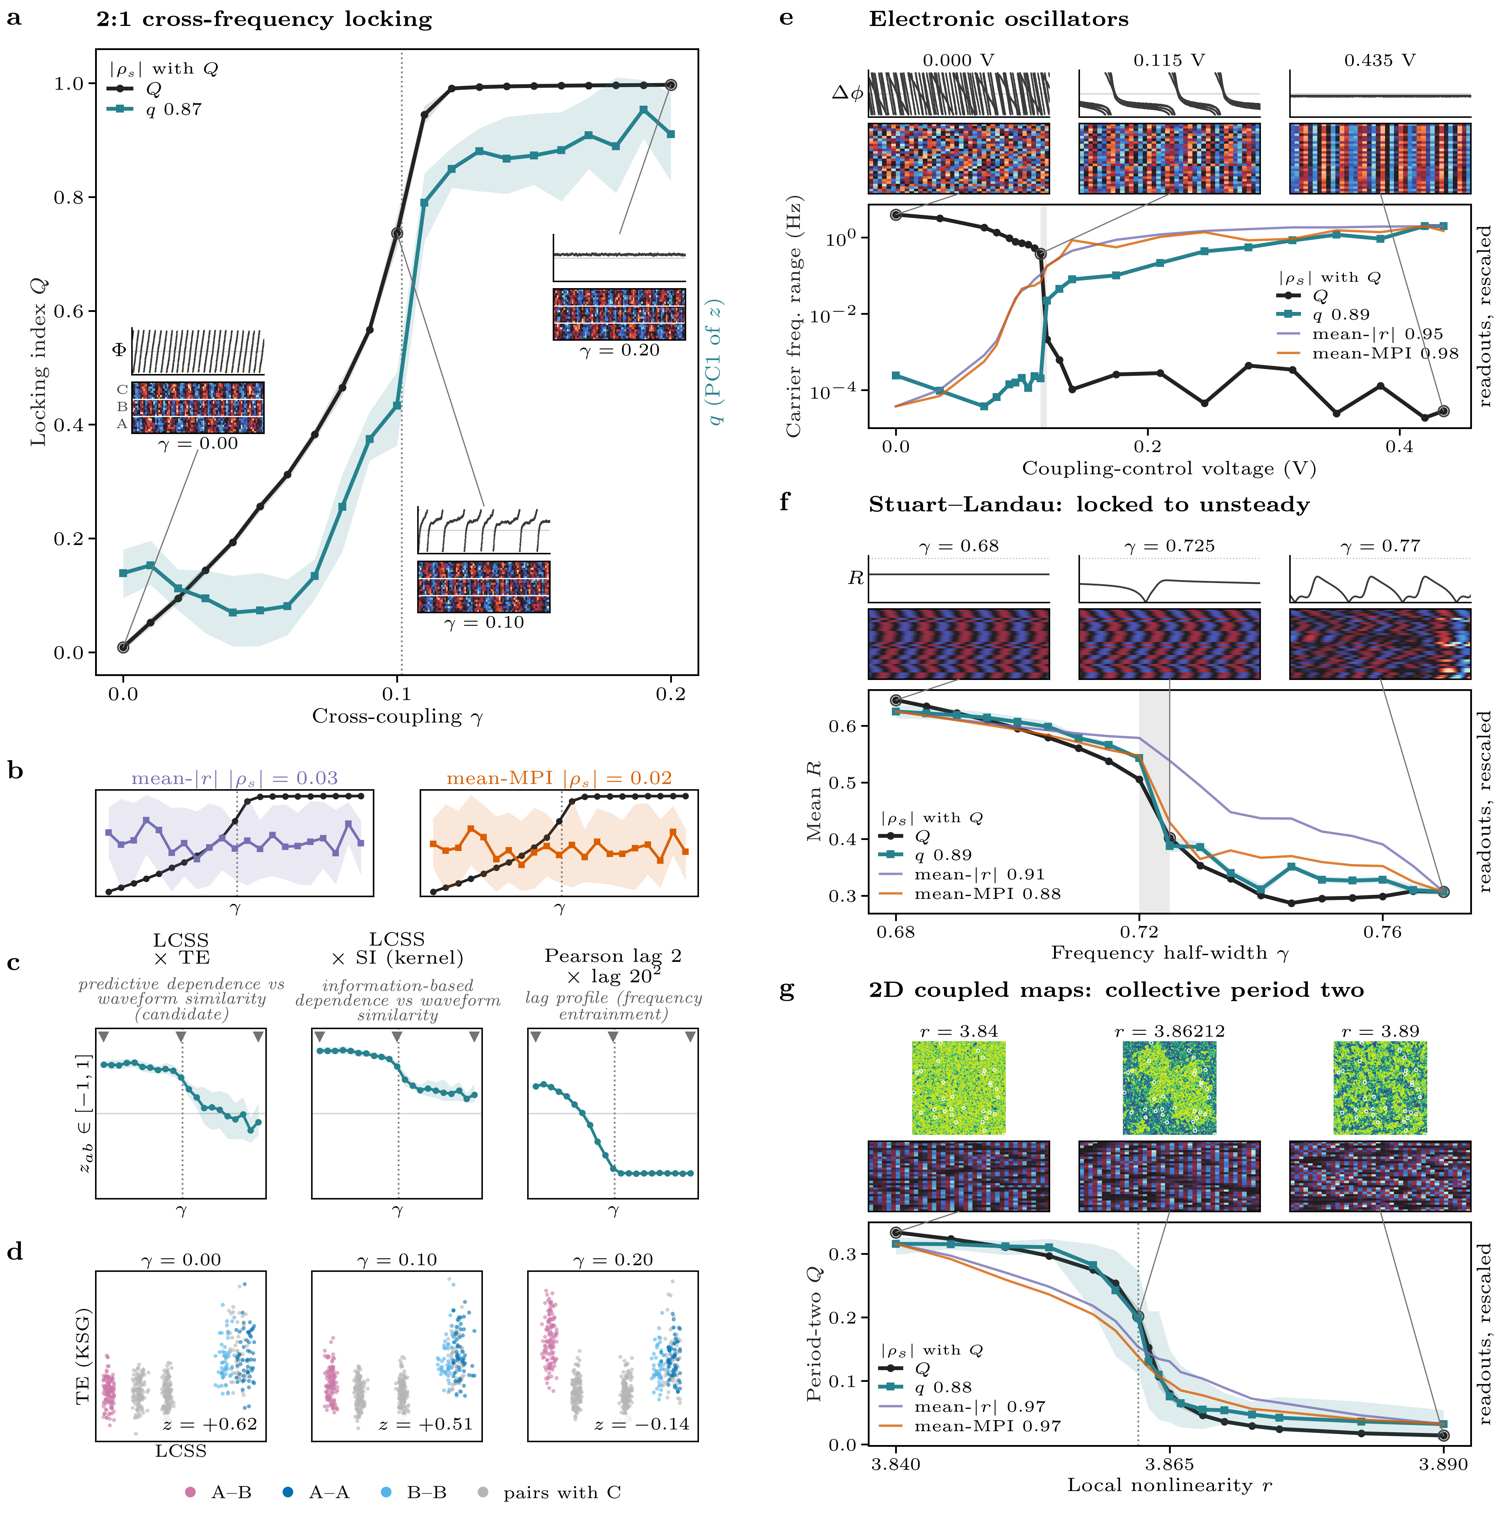

In [11]:
si = cf.Feature('lcss', 'si_kernel_W-0.5_k-1', 'LCSS\n$\\times$ SI (kernel)', 'information-based dependence vs waveform similarity')
locking_si = cf.load('locking', features=(cf.LOCKING_FEATURES[0], si, cf.LOCKING_FEATURES[2]))
locking_si.spec = cf.replace(locking_si.spec, name='locking-lcss-si')
show(cf.save(cf.composite_stacked(locking_si, [hardware, sl, cml]), 'composite-stacked-lcss-si'))

## Export individual panels

In [12]:
written = {'locking': cf.export_panels(locking), 'locking-lcss-si': cf.export_panels(locking_si)}
for name in ('hardware', 'stuart-landau', 'kuramoto', 'cml2d'):
    written[name] = cf.export_panels(systems[name], stacked=True)
receipt = cf.receipt(list(systems.values()))
print({k: len(v) for k, v in written.items()}, 'panels (each as SVG, PDF and 600-dpi PNG) under', cf.OUT/'panels')
print('provenance:', receipt.relative_to(ROOT))

{'locking': 33, 'locking-lcss-si': 33, 'hardware': 17, 'stuart-landau': 9, 'kuramoto': 9, 'cml2d': 13} panels (each as SVG, PDF and 600-dpi PNG) under /Users/wedi0306/Code/mts-spi-study-cluster/results/order-parameter-inference/composites-261021/panels
provenance: results/order-parameter-inference/composites-261021/provenance.json


## Figure folder: three typographies

`figure-261029/` holds the figure above (version A) and its panels in three renditions: Computer Modern (`cm/`), Helvetica text with Computer Modern math (`helvetica/`), and Helvetica text with sans-serif math (`helvetica-sansmath/`, `newtxsf`). Tick numbers are Helvetica in both Helvetica renditions. Its `README.md` maps panel letters to files.

In [13]:
figure = cf.export_figure(locking, [hardware, sl, cml])
print(figure.relative_to(ROOT), sorted(p.name for p in figure.iterdir()))

results/order-parameter-inference/figure-261029 ['README.md', 'cm', 'helvetica', 'helvetica-sansmath', 'provenance.json']


## Open choices

Decided (2026-10-21): Stuart–Landau over Kuramoto; wrapped $\Phi$ and the other default glyphs; bands; locking snapshots at $\gamma=0,.10,.20$.

1. **Hardware $Q$ and range.** Frequency range on settings ≤ 87 (recommended), $R_1$, or the full sweep.
2. **Feature titles.** Spell out the SPIs: LCSS similarity (unconstrained) × KSG transfer entropy (4 neighbours, history 1); Johansen max-eigenvalue statistic (constant term, 10 lagged differences) × trace statistic (linear trend, 1 lagged difference); Pearson $r$ at lag 2 × squared Pearson $r$ at lag 20 (samples, i.e. 1 and 10 time units); kernel stochastic interaction × interdependence score; Pearson $r$ at 2 ms × 20 ms.
3. **$Q$ definitions.** In the caption or methods rather than in-panel: each needs symbols that only the caption can define.